# Final risk evaluation and performance

In [2]:
# 1. Enable Auto-reloading
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import matplotlib.pyplot as plt

# Add the project root to Python path
project_root = Path.cwd().parent  # Goes up one level from notebooks/
sys.path.insert(0, str(project_root))

# 2. Import your heavy logic from your Python file
from core.gnn_layer.risk_predict import (
    fetch_graph_from_neo4j, 
    RiskEscalationGNN, 
    train_model,
    graph_edge_oversample, 
    evaluate_with_kfold,
    generate_threat_report
)

from core.kg_sna_layer.graph_builder import(
    calculate_strict_fold_topology,
    wipe_sna_metrics
)

print("Environment linked and modules loaded successfully!")

import torch
import random
import numpy as np

# Lock the random seed for 100% reproducibility
seed = 42
torch.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)

print("Random seed set!")

c:\Users\dhara\anaconda3\envs\sna_oms_thesis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Environment linked and modules loaded successfully!
Random seed set!


In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from datetime import datetime
from core.config import graph_base
import torch
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve, roc_curve, auc, average_precision_score
from scipy.ndimage import gaussian_filter1d

print("⏳ Fetching Graph from Neo4j...")
data_baseline, data_enriched, reverse_mapping = fetch_graph_from_neo4j(graph_base.URL, graph_base.USER, graph_base.PASS)
print(f"✅ Graph Fetched: {data_baseline.x.size(0)} Nodes, {data_baseline.edge_index.size(1)} Edges.")

print("⏳ Scaling Enriched NLP Node Features...")
scaler = StandardScaler()
# We scale the Extremist and Contraband counts so they don't overpower the GNN
scaled_features = scaler.fit_transform(data_enriched.x.numpy())
data_enriched.x = torch.tensor(scaled_features, dtype=torch.float)
print(f"✅ Baseline Node Features: {data_baseline.x.size(1)} (Dummy Variable)")
print(f"✅ Enriched Node Features: {data_enriched.x.size(1)} (Scaled NLP Taxonomy Counts)")

⏳ Fetching Graph from Neo4j...
✅ Graph Fetched: 770 Nodes, 2387 Edges.
⏳ Scaling Enriched NLP Node Features...
✅ Baseline Node Features: 1 (Dummy Variable)
✅ Enriched Node Features: 1 (Scaled NLP Taxonomy Counts)


In [4]:
def plot_dynamic_feature_distributions(data_baseline):
    print("⏳ Simulating a safe training fold to extract leak-proof features...")
    
    # 1. Simulate a single 80/20 train split (Stratified by class)
    indices = np.arange(data_baseline.edge_index.size(1))
    y_array = data_baseline.y.numpy().flatten()
    train_idx, _ = train_test_split(indices, test_size=0.2, stratify=y_array, random_state=42)
    
    train_edge_index = data_baseline.edge_index[:, train_idx]

    train_edge_weights = data_baseline.edge_weight[train_idx]


    num_nodes = data_baseline.x.size(0)
    
    # 2. Calculate the 6 dynamic features safely!
    # Returns: [CN, Jaccard, Betw(src), Betw(tgt), Eigen(src), Eigen(tgt)]
    train_edge_attr = calculate_strict_fold_topology(train_edge_index, train_edge_index, num_nodes, train_edge_weights )
    
    # 3. Convert the PyTorch tensor into a Pandas DataFrame for easy plotting
    feature_names = [
        'Common Neighbors', 
        'Jaccard Index', 
        'Source Betweenness', 
        'Target Betweenness', 
        'Source Eigenvector', 
        'Target Eigenvector',
        'Aggressiveness',
        'Reputation'
    ]
    df_features = pd.DataFrame(train_edge_attr.numpy(), columns=feature_names)
    
    # 4. Set up the Academic Aesthetic (Matching your provided image)
    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(2, 4, figsize=(20, 12))
    fig.suptitle('Continuous Data Distribution of Input SNA Metrics (Post-Split Training Data)', 
                 fontsize=18, fontweight='bold', y=0.98)
    
    axes = axes.flatten()
    
    # Professional Purple Color
    plot_color = '#a37bc4' 
    line_color = '#6a0dad'

    # 5. Loop through and plot all 6 features (now 8)
    for i, col in enumerate(feature_names):
        ax = axes[i]
        
        # We use a custom KDE line color and histogram bar color to match your aesthetic
        sns.histplot(df_features[col], kde=True, ax=ax, color=plot_color, 
                     edgecolor='white', bins=30, alpha=0.8, line_kws={'color': line_color})
        
        ax.set_title(f'Distribution: {col}', fontsize=14, pad=10)
        ax.set_xlabel('Score', fontsize=12)
        ax.set_ylabel('Frequency (Edges)', fontsize=12)
        
    plt.tight_layout(pad=3.0)
    
    # Optional: Save the plot
    # plt.savefig("post_split_feature_distributions.png", dpi=300, bbox_inches='tight')
    
    return fig

# Execute the plotter using your already-fetched baseline data
#fig_dists = plot_dynamic_feature_distributions(data_baseline)
#timestamp_dist = datetime.now().strftime("%Y%m%d_%H%M%S")
#plt.savefig(f"{timestamp_dist}_feature_distributions.png", dpi=300, bbox_inches='tight')
#plt.show()

## Baseline Reality

## Model convergence

In [8]:
def smooth_curve(points, factor=0.85):
    """
    Applies Exponential Moving Average (EMA) to smooth out training noise.
    """
    smoothed_points = []
    for point in points:
        if smoothed_points:
            previous = smoothed_points[-1]
            smoothed_points.append(previous * factor + point * (1 - factor))
        else:
            smoothed_points.append(point)
    return smoothed_points

def plot_model_convergence(all_histories, title="GNN Model Convergence (Averaged across K-Folds)"):
    """
    Plots the Averaged Loss and Accuracy convergence across all K-Folds, 
    applying EMA smoothing while keeping raw data faintly visible.
    """
    epochs = len(all_histories[0]['loss'])
    
    # 1. Average the metrics across all 5 folds
    raw_loss = np.mean([h['loss'] for h in all_histories], axis=0)
    raw_acc = np.mean([h['acc'] for h in all_histories], axis=0)
    
    # 2. Apply Smoothing
    smoothed_loss = smooth_curve(raw_loss, factor=0.85)
    smoothed_acc = smooth_curve(raw_acc, factor=0.85)
    
    fig, ax1 = plt.subplots(figsize=(10, 6))

    # --- Plot Loss on primary Y-axis (Green) ---
    color_loss = '#2ca02c'
    ax1.set_xlabel('Training Epochs', fontsize=12, fontweight='bold')
    ax1.set_ylabel('BCE Loss', color=color_loss, fontsize=12, fontweight='bold')
    
    # Faint raw data
    ax1.plot(range(1, epochs + 1), raw_loss, color=color_loss, alpha=0.2, linewidth=1.5)
    # Bold smoothed trend
    line1 = ax1.plot(range(1, epochs + 1), smoothed_loss, color=color_loss, linewidth=2.5, label='Training Loss (Smoothed)')
    ax1.tick_params(axis='y', labelcolor=color_loss)
    
    ax1.grid(True, linestyle='--', alpha=0.4, color='gray')

    # --- Plot Accuracy on secondary Y-axis (Blue) ---
    ax2 = ax1.twinx()  
    color_acc = '#808080' # Professional muted blue
    ax2.set_ylabel('Accuracy', color=color_acc, fontsize=12, fontweight='bold')
    
    # Faint raw data
    ax2.plot(range(1, epochs + 1), raw_acc, color=color_acc, alpha=0.2, linewidth=1.5)
    # Bold smoothed trend
    line2 = ax2.plot(range(1, epochs + 1), smoothed_acc, color=color_acc, linewidth=2.5, linestyle='-', label='Training Accuracy (Smoothed)')
    ax2.tick_params(axis='y', labelcolor=color_acc)
    
    # --- Formatting ---
    lines = line1 + line2
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='center right', framealpha=0.9, fontsize=11)

    plt.title(title, fontsize=15, pad=20, fontweight='bold')
    fig.tight_layout()
    
    return fig

#print("⏳ Fetching safe baseline graph from Neo4j...")
# We fetch from Neo4j. We will ignore data_enriched here because we want 
# the K-Fold loop to build the enriched metrics dynamically without leakage!
#data_baseline, _, reverse_mapping = fetch_graph_from_neo4j(graph_base.URL, graph_base.USER, graph_base.PASS)

#print(f"✅ Baseline Graph Fetched: {data_baseline.x.size(0)} Nodes, {data_baseline.edge_index.size(1)} Edges.")

#print("Step 3: Initializing GNN and starting Leak-Proof Validation...")


# 1. Initialize template model
#model_template = RiskEscalationGNN(
#    num_node_features=data_baseline.x.size(1), 
#    hidden_channels=32, 
#    edge_dim=6  # 6 Dynamic Features: [CN, Jaccard, Betw(src), Betw(tgt), Eigen(src), Eigen(tgt)]
#)
# Make sure in_channels matches your Node Features (e.g., Betweenness, Eigenvector, etc.)
# Make sure edge_dim matches the dynamic features (e.g., Jaccard, Common Neighbors = 2)

# 2. Run the dynamic, leak-proof K-Fold
# This will take a moment as it calculates math and trains 5 distinct models
#y_true, y_probs, all_histories = evaluate_with_kfold(
#    model_template, 
#    data_baseline, 
#    n_splits=5, 
#    epochs=150
#)

#print("✅ Validation Complete! Plotting Convergence...")

# 3. Render the convergence graph
#fig_convergence = plot_model_convergence(all_histories)
#timestamp_dist = datetime.now().strftime("%Y%m%d_%H%M%S")
#plt.savefig(f"{timestamp_dist}_convergence_loss_smoothed.png", dpi=300, bbox_inches='tight')
#plt.show()

## Threshold calibration

In [9]:
def plot_threshold_calibration(y_true, y_probs):
    """
    Plots Precision, Recall, and F1-Score across all thresholds to find the optimal decision boundary.
    """
    # 1. Calculate metrics at various thresholds
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_probs)
    
    # Calculate F1 Score safely (avoiding division by zero)
    f1_scores = np.divide(
        2 * (precisions[:-1] * recalls[:-1]),
        (precisions[:-1] + recalls[:-1]),
        out=np.zeros_like(precisions[:-1]),
        where=(precisions[:-1] + recalls[:-1]) != 0
    )
    
    # 2. Find the Optimal Threshold (Maximizing F1)
    optimal_idx = np.argmax(f1_scores)
    optimal_threshold = thresholds[optimal_idx]
    optimal_f1 = f1_scores[optimal_idx]
    
    # 3. Set up the plot aesthetic
    sns.set_theme(style="whitegrid")
    fig, ax = plt.subplots(figsize=(10, 6))
    
    # 4. Plot the curves
    ax.plot(thresholds, precisions[:-1], '--', color='tab:blue', label='Precision', linewidth=2)
    ax.plot(thresholds, recalls[:-1], '--', color='tab:orange', label='Recall', linewidth=2)
    ax.plot(thresholds, f1_scores, '-', color='tab:green', label='F1-Score', linewidth=3.5)
    
    # 5. Plot the Optimal Threshold Line
    ax.axvline(optimal_threshold, color='red', linestyle=':', linewidth=2.5, 
               label=f'Optimal Threshold ({optimal_threshold:.3f})')
    
    ax.set_title('Threshold Calibration: Precision-Recall Tradeoff', fontsize=16, pad=15, fontweight='bold')
    ax.set_xlabel('Classification Threshold', fontsize=13)
    ax.set_ylabel('Score', fontsize=13)
    ax.set_xlim([-0.05, 1.05])
    ax.set_ylim([-0.05, 1.05])
    
    ax.legend(loc='lower center', fontsize=12, framealpha=0.9)
    plt.tight_layout()
    
    # Optional: plt.savefig("threshold_calibration.png", dpi=300, bbox_inches='tight')
    
    print(f"✅ Optimal Threshold Found: {optimal_threshold:.3f} (F1: {optimal_f1:.3f})")
    return fig, optimal_threshold

# Execute it using your concatenated K-Fold arrays
#fig_thresh, optimal_threshold = plot_threshold_calibration(y_true, y_probs)
#timestamp_dist = datetime.now().strftime("%Y%m%d_%H%M%S")
#plt.savefig(f"{timestamp_dist}_threshold_calibration.png", dpi=300, bbox_inches='tight')
#plt.show()

## Final evaluation curves

In [10]:
def plot_final_evaluation_curves(y_true, y_probs, optimal_threshold):
    """
    Generates side-by-side ROC and Precision-Recall Curves using the global OOF predictions.
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))
    sns.set_theme(style="whitegrid")
    
    # ==========================================
    # CHART 1: ROC CURVE
    # ==========================================
    fpr, tpr, _ = roc_curve(y_true, y_probs)
    roc_auc = auc(fpr, tpr)
    
    ax1.plot(fpr, tpr, color='#2ca02c', linewidth=3.5, label=f'OOF ROC Curve (AUC = {roc_auc:.2f})')
    ax1.plot([0, 1], [0, 1], 'r:', linewidth=2, label='Random Guess')
    
    # Add a marker for where our Optimal Threshold sits on the ROC curve
    opt_fpr, opt_tpr, _ = roc_curve(y_true, y_probs >= optimal_threshold)
    ax1.plot(opt_fpr[1], opt_tpr[1], marker='o', markersize=10, color='red', 
             label=f'Threshold ({optimal_threshold:.3f})')
    
    ax1.set_title('Global Out-Of-Fold ROC Curve', fontsize=16, fontweight='bold', pad=15)
    ax1.set_xlabel('False Positive Rate', fontsize=13)
    ax1.set_ylabel('True Positive Rate (Recall)', fontsize=13)
    ax1.legend(loc='lower right', fontsize=12, framealpha=0.9)
    ax1.set_xlim([-0.05, 1.05])
    ax1.set_ylim([-0.05, 1.05])

    # ==========================================
    # CHART 2: PRECISION-RECALL (PR) CURVE
    # ==========================================
    precisions, recalls, _ = precision_recall_curve(y_true, y_probs)
    pr_auc = average_precision_score(y_true, y_probs)
    baseline_pr = np.mean(y_true) # The ratio of actual violent edges
    
    ax2.plot(recalls, precisions, color='#9467bd', linewidth=3.5, label=f'OOF PR Curve (AP = {pr_auc:.2f})')
    ax2.axhline(baseline_pr, color='red', linestyle=':', linewidth=2, 
                label=f'Random Guess (Baseline PR = {baseline_pr:.2f})')
    
    # Add a marker for where our Optimal Threshold sits on the PR curve
    opt_p, opt_r, _ = precision_recall_curve(y_true, y_probs >= optimal_threshold)
    # The optimal point is usually the second item in these specific arrays
    ax2.plot(opt_r[1], opt_p[1], marker='o', markersize=10, color='red', 
             label=f'Threshold ({optimal_threshold:.3f})')

    ax2.set_title('Global Out-Of-Fold PR Curve', fontsize=16, fontweight='bold', pad=15)
    ax2.set_xlabel('Recall (How many actual threats did we catch?)', fontsize=13)
    ax2.set_ylabel('Precision (When we alert, how often are we right?)', fontsize=13)
    ax2.legend(loc='upper right', fontsize=12, framealpha=0.9)
    ax2.set_xlim([-0.05, 1.05])
    ax2.set_ylim([-0.05, 1.05])

    plt.tight_layout(pad=3.0)
    
    # Optional: plt.savefig("final_evaluation_dual.png", dpi=300, bbox_inches='tight')
    return fig

# Execute using the threshold we found in Step 4A
#fig_curves = plot_final_evaluation_curves(y_true, y_probs, optimal_threshold)
#timestamp_dist = datetime.now().strftime("%Y%m%d_%H%M%S")
#plt.savefig(f"{timestamp_dist}_evaluation_dual.png", dpi=300, bbox_inches='tight')
#plt.show()

 CHAPTER 1: EVALUATING THE BASELINE MODEL 
Epoch 000 | Loss: 0.6970
Epoch 020 | Loss: 0.6847
Epoch 040 | Loss: 0.6741
Epoch 060 | Loss: 0.6871
Epoch 080 | Loss: 0.6720
Epoch 100 | Loss: 0.6829
Epoch 120 | Loss: 0.6566
Epoch 140 | Loss: 0.6722
Epoch 000 | Loss: 0.6981
Epoch 020 | Loss: 0.6895
Epoch 040 | Loss: 0.6897
Epoch 060 | Loss: 0.6803
Epoch 080 | Loss: 0.6693
Epoch 100 | Loss: 0.6819
Epoch 120 | Loss: 0.6801
Epoch 140 | Loss: 0.6892
Epoch 000 | Loss: 0.6987
Epoch 020 | Loss: 0.6823
Epoch 040 | Loss: 0.6851
Epoch 060 | Loss: 0.7050
Epoch 080 | Loss: 0.6918
Epoch 100 | Loss: 0.7030
Epoch 120 | Loss: 0.6671
Epoch 140 | Loss: 0.6749
Epoch 000 | Loss: 0.6944
Epoch 020 | Loss: 0.7001
Epoch 040 | Loss: 0.6828
Epoch 060 | Loss: 0.6588
Epoch 080 | Loss: 0.6861
Epoch 100 | Loss: 0.6869
Epoch 120 | Loss: 0.6589
Epoch 140 | Loss: 0.6552
Epoch 000 | Loss: 0.6977
Epoch 020 | Loss: 0.6787
Epoch 040 | Loss: 0.6922
Epoch 060 | Loss: 0.6829
Epoch 080 | Loss: 0.6780
Epoch 100 | Loss: 0.6929
Epoch 1

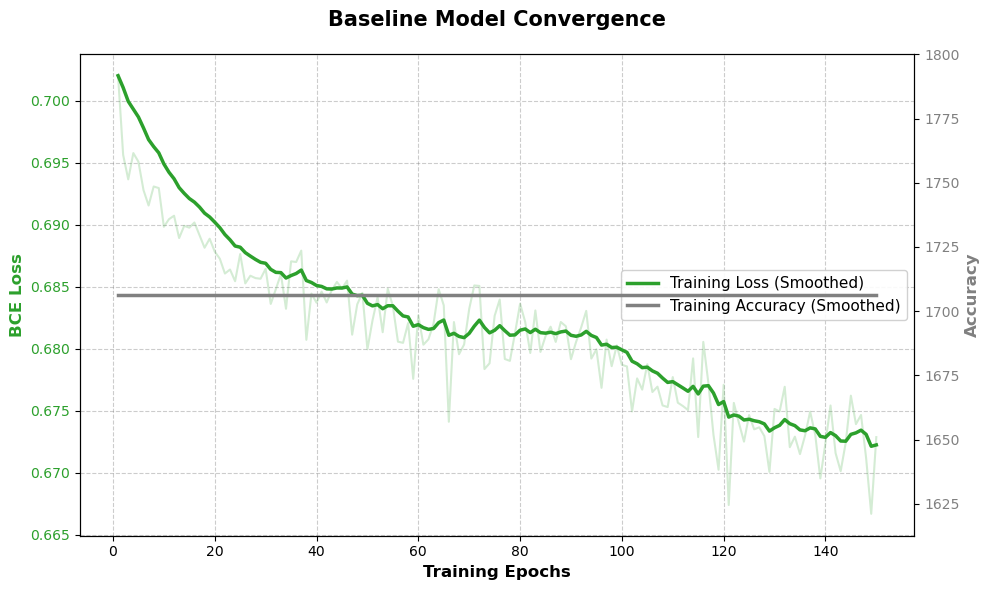

✅ Optimal Threshold Found: 0.406 (F1: 0.199)


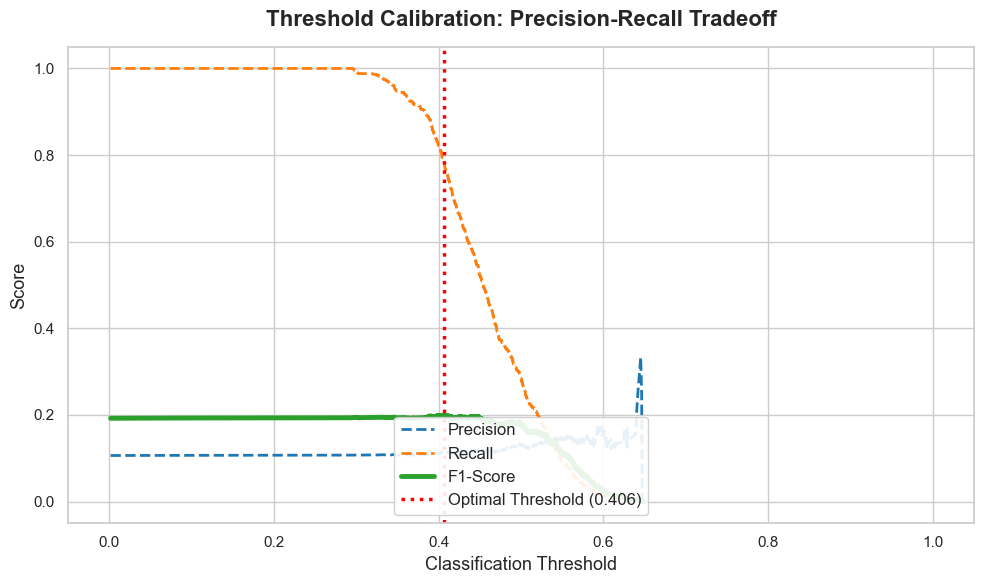

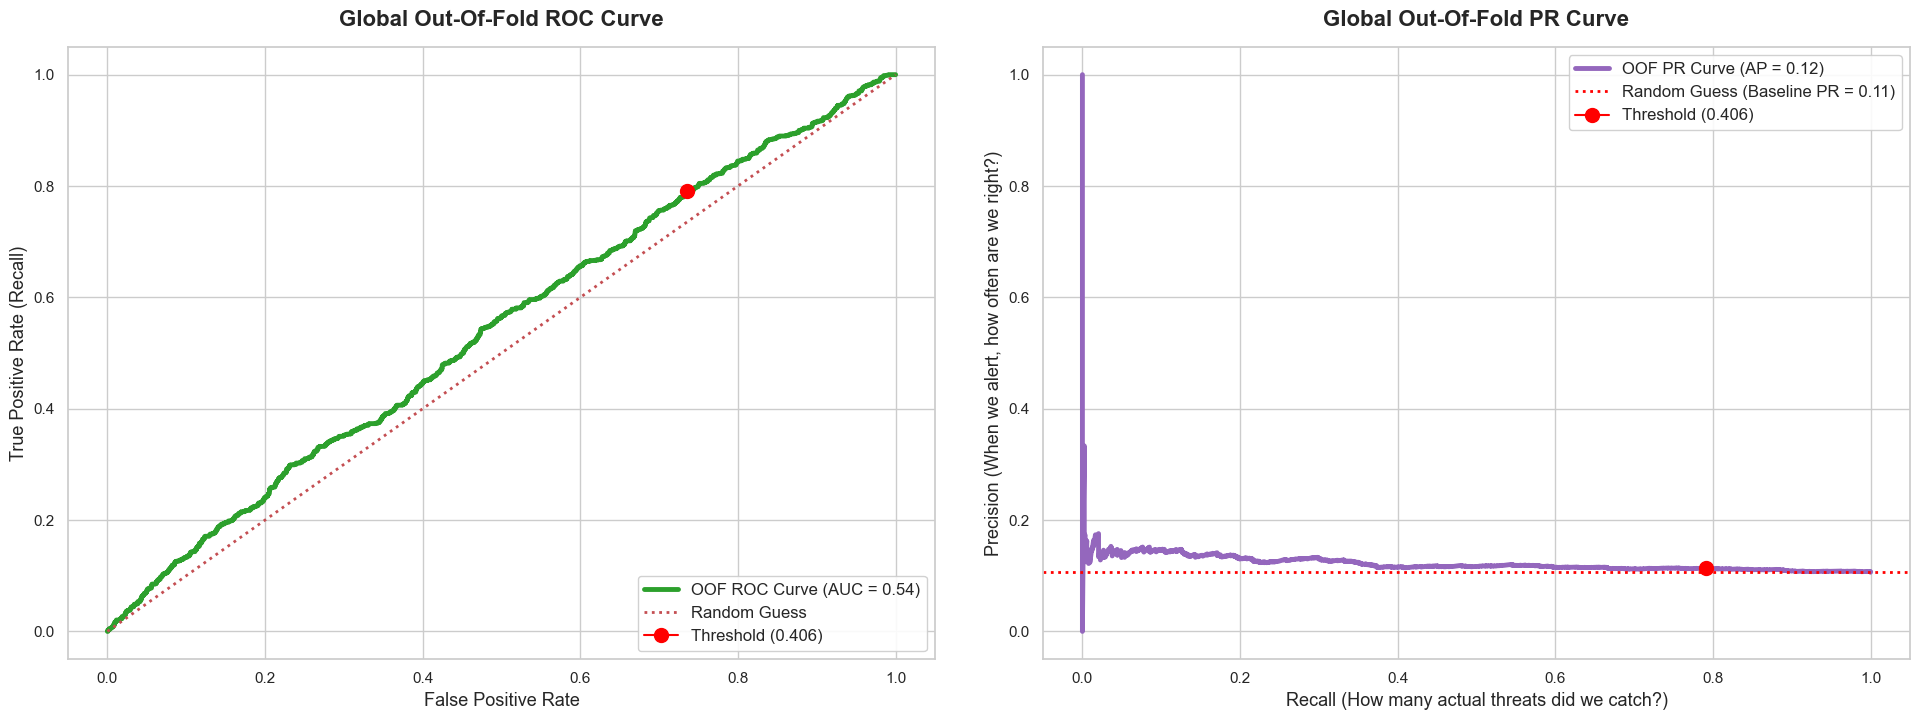

In [11]:
print("==========================================")
print(" CHAPTER 1: EVALUATING THE BASELINE MODEL ")
print("==========================================")

# 1. Initialize Baseline (edge_dim=6 for pure topology)
baseline_model = RiskEscalationGNN(
    num_node_features=data_baseline.x.size(1), 
    hidden_channels=32, 
    edge_dim=6  # <--- FIXED: Pure Topology only
)

# 2. Run the K-Fold
y_true_base, y_probs_base, histories_base = evaluate_with_kfold(
    baseline_model, 
    data_baseline, 
    n_splits=5, 
    epochs=150,
    is_enriched=False # <--- FIXED: Blinds the model to NLP weights
)

# 3. Plot Baseline Diagnostics
print("✅ Baseline Training Complete. Generating Diagnostics...")
timestamp_dist = datetime.now().strftime("%Y%m%d_%H%M%S")
fig_convergence = plot_model_convergence(histories_base, title="Baseline Model Convergence")
plt.savefig(f"{timestamp_dist}_convergence.png", dpi=300, bbox_inches='tight')
plt.show()

fig_thresh, opt_thresh_base = plot_threshold_calibration(y_true_base, y_probs_base)
plt.savefig(f"{timestamp_dist}_threshold_calibration.png", dpi=300, bbox_inches='tight')
plt.show()

fig_eval = plot_final_evaluation_curves(y_true_base, y_probs_base, opt_thresh_base)
plt.savefig(f"{timestamp_dist}_evaluation_dual.png", dpi=300, bbox_inches='tight')
plt.show()

## The enriched reality

 CHAPTER 2: TRAINING THE ENRICHED MODEL   
Epoch 000 | Loss: 1.2858
Epoch 020 | Loss: 0.6945
Epoch 040 | Loss: 0.6420
Epoch 060 | Loss: 0.6291
Epoch 080 | Loss: 0.6297
Epoch 100 | Loss: 0.6226
Epoch 120 | Loss: 0.6095
Epoch 140 | Loss: 0.6102
Epoch 000 | Loss: 1.1036
Epoch 020 | Loss: 0.6442
Epoch 040 | Loss: 0.6389
Epoch 060 | Loss: 0.6076
Epoch 080 | Loss: 0.6091
Epoch 100 | Loss: 0.5905
Epoch 120 | Loss: 0.5924
Epoch 140 | Loss: 0.5731
Epoch 000 | Loss: 1.1195
Epoch 020 | Loss: 0.6598
Epoch 040 | Loss: 0.6314
Epoch 060 | Loss: 0.6249
Epoch 080 | Loss: 0.6251
Epoch 100 | Loss: 0.6047
Epoch 120 | Loss: 0.6021
Epoch 140 | Loss: 0.5990
Epoch 000 | Loss: 1.7420
Epoch 020 | Loss: 0.7224
Epoch 040 | Loss: 0.6541
Epoch 060 | Loss: 0.6281
Epoch 080 | Loss: 0.6237
Epoch 100 | Loss: 0.6143
Epoch 120 | Loss: 0.6005
Epoch 140 | Loss: 0.6103
Epoch 000 | Loss: 1.0148
Epoch 020 | Loss: 0.6530
Epoch 040 | Loss: 0.6420
Epoch 060 | Loss: 0.6372
Epoch 080 | Loss: 0.6026
Epoch 100 | Loss: 0.6146
Epoch 1

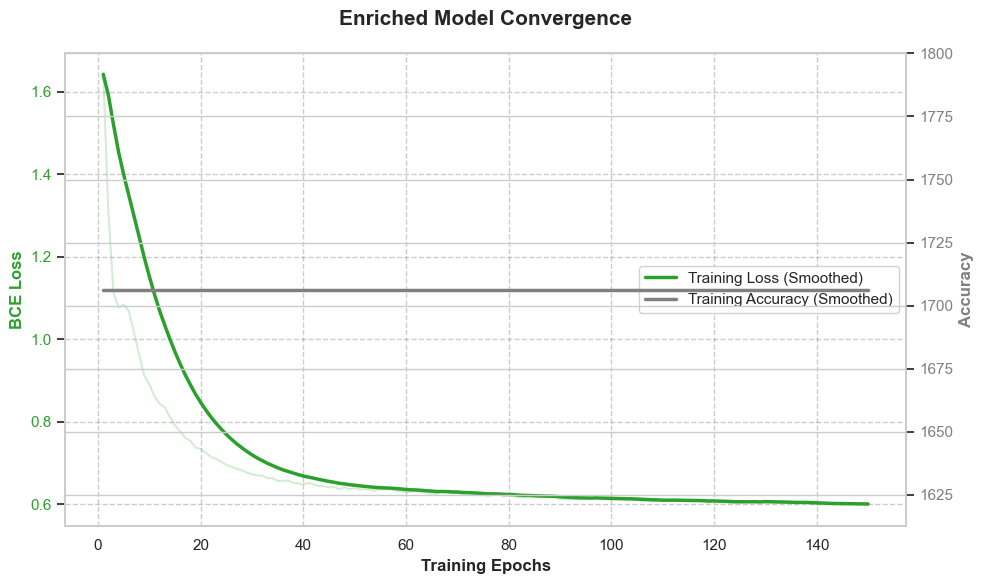

In [12]:
print("==========================================")
print(" CHAPTER 2: TRAINING THE ENRICHED MODEL   ")
print("==========================================")

# 1. Initialize Enriched (edge_dim=8 for Topology + Dynamic Aggressiveness/Reputation)
enriched_model = RiskEscalationGNN(
    num_node_features=data_enriched.x.size(1), 
    hidden_channels=32, 
    edge_dim=8  # <--- FIXED: 6 Topology + 2 NLP Edge Features
)

# 2. Run the K-Fold
y_true_enr, y_probs_enr, histories_enr = evaluate_with_kfold(
    enriched_model, 
    data_enriched, 
    n_splits=5, 
    epochs=150,
    is_enriched=True # <--- FIXED: Injects the LLM risk weights
)

print("✅ Enriched Training Complete. Generating Convergence...")
timestamp_dist = datetime.now().strftime("%Y%m%d_%H%M%S")
fig_conv_enr = plot_model_convergence(histories_enr, title="Enriched Model Convergence")
plt.savefig(f"{timestamp_dist}_convergence_enriched.png", dpi=300, bbox_inches='tight')
plt.show()

## The final study

In [13]:
def plot_ablation_evaluation(y_true_base, y_probs_base, y_true_enr, y_probs_enr):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))
    sns.set_theme(style="whitegrid")
    
    # --- Helper: Optimal Threshold ---
    def get_optimal_threshold(y_t, y_p):
        precisions, recalls, thresholds = precision_recall_curve(y_t, y_p)
        f1_scores = np.divide(2 * (precisions[:-1] * recalls[:-1]), (precisions[:-1] + recalls[:-1]),
                              out=np.zeros_like(precisions[:-1]), where=(precisions[:-1] + recalls[:-1]) != 0)
        return thresholds[np.argmax(f1_scores)]

    opt_thresh_base = get_optimal_threshold(y_true_base, y_probs_base)
    opt_thresh_enr = get_optimal_threshold(y_true_enr, y_probs_enr)
    print(f"✅ Optimal Thresholds Found: Baseline {opt_thresh_base:.3f} | Enriched {opt_thresh_enr:.3f}")

    # --- Smoothing Factor ---
    # Higher sigma = softer line. 2 to 3 is a good balance of smoothness without distorting reality.
    smooth_sigma = 2.5 

    # ==========================================
    # CHART 1: ROC CURVE COMPARISON
    # ==========================================
    # Baseline (Grey)
    fpr_b, tpr_b, _ = roc_curve(y_true_base, y_probs_base)
    roc_auc_b = auc(fpr_b, tpr_b)
    tpr_b_smooth = gaussian_filter1d(tpr_b, sigma=smooth_sigma) # Smooth the line
    ax1.plot(fpr_b, tpr_b_smooth, color='gray', linestyle='--', linewidth=2.5, 
             label=f'Baseline ROC (AUC = {roc_auc_b:.2f})')
    
    opt_fpr_b, opt_tpr_b, _ = roc_curve(y_true_base, y_probs_base >= opt_thresh_base)
    ax1.plot(opt_fpr_b[1], opt_tpr_b[1], marker='o', markersize=8, color='gray', markeredgecolor='black')

    # Enriched (Purple)
    fpr_e, tpr_e, _ = roc_curve(y_true_enr, y_probs_enr)
    roc_auc_e = auc(fpr_e, tpr_e)
    tpr_e_smooth = gaussian_filter1d(tpr_e, sigma=smooth_sigma) # Smooth the line
    ax1.plot(fpr_e, tpr_e_smooth, color='#2ca02c', linewidth=3.5, 
             label=f'Enriched ROC (AUC = {roc_auc_e:.2f})')
    
    opt_fpr_e, opt_tpr_e, _ = roc_curve(y_true_enr, y_probs_enr >= opt_thresh_enr)
    ax1.plot(opt_fpr_e[1], opt_tpr_e[1], marker='o', markersize=10, color='red', 
             label=f'Enriched Threshold ({opt_thresh_enr:.3f})')
    
    ax1.plot([0, 1], [0, 1], 'r:', linewidth=2, label='Random Guess')
    ax1.set_title('Ablation Study: ROC Curve Comparison', fontsize=16, fontweight='bold', pad=15)
    ax1.set_xlabel('False Positive Rate', fontsize=13)
    ax1.set_ylabel('True Positive Rate (Recall)', fontsize=13)
    ax1.legend(loc='lower right', fontsize=12, framealpha=0.9)

    # ==========================================
    # CHART 2: PR CURVE COMPARISON
    # ==========================================
    baseline_pr = np.mean(y_true_base) 
    
    # Baseline (Grey)
    prec_b, rec_b, _ = precision_recall_curve(y_true_base, y_probs_base)
    pr_auc_b = average_precision_score(y_true_base, y_probs_base)
    prec_b_smooth = gaussian_filter1d(prec_b, sigma=smooth_sigma) # Smooth the line
    ax2.plot(rec_b, prec_b_smooth, color='gray', linestyle='--', linewidth=2.5, 
             label=f'Baseline PR (AP = {pr_auc_b:.2f})')
    
    opt_p_b, opt_r_b, _ = precision_recall_curve(y_true_base, y_probs_base >= opt_thresh_base)
    ax2.plot(opt_r_b[1], opt_p_b[1], marker='o', markersize=8, color='gray', markeredgecolor='black')

    # Enriched (Purple)
    prec_e, rec_e, _ = precision_recall_curve(y_true_enr, y_probs_enr)
    pr_auc_e = average_precision_score(y_true_enr, y_probs_enr)
    prec_e_smooth = gaussian_filter1d(prec_e, sigma=smooth_sigma) # Smooth the line
    
    # Use drawstyle='steps-post' for a classic, clean PR curve look
    ax2.plot(rec_e, prec_e_smooth, color='#9467bd', linewidth=3.5, 
             label=f'Enriched PR (AP = {pr_auc_e:.2f})')
    
    opt_p_e, opt_r_e, _ = precision_recall_curve(y_true_enr, y_probs_enr >= opt_thresh_enr)
    ax2.plot(opt_r_e[1], opt_p_e[1], marker='o', markersize=10, color='red', 
             label=f'Enriched Threshold ({opt_thresh_enr:.3f})')
    
    ax2.axhline(baseline_pr, color='red', linestyle=':', linewidth=2, 
                label=f'Random Guess (AP = {baseline_pr:.2f})')

    ax2.set_title('Ablation Study: Precision-Recall Comparison', fontsize=16, fontweight='bold', pad=15)
    ax2.set_xlabel('Recall (How many actual threats did we catch?)', fontsize=13)
    ax2.set_ylabel('Precision (When we alert, how often are we right?)', fontsize=13)
    ax2.legend(loc='upper right', fontsize=12, framealpha=0.9)

    plt.tight_layout(pad=3.0)
    return fig

 CHAPTER 3: THE FINAL ABLATION STUDY      
✅ Optimal Thresholds Found: Baseline 0.406 | Enriched 0.547


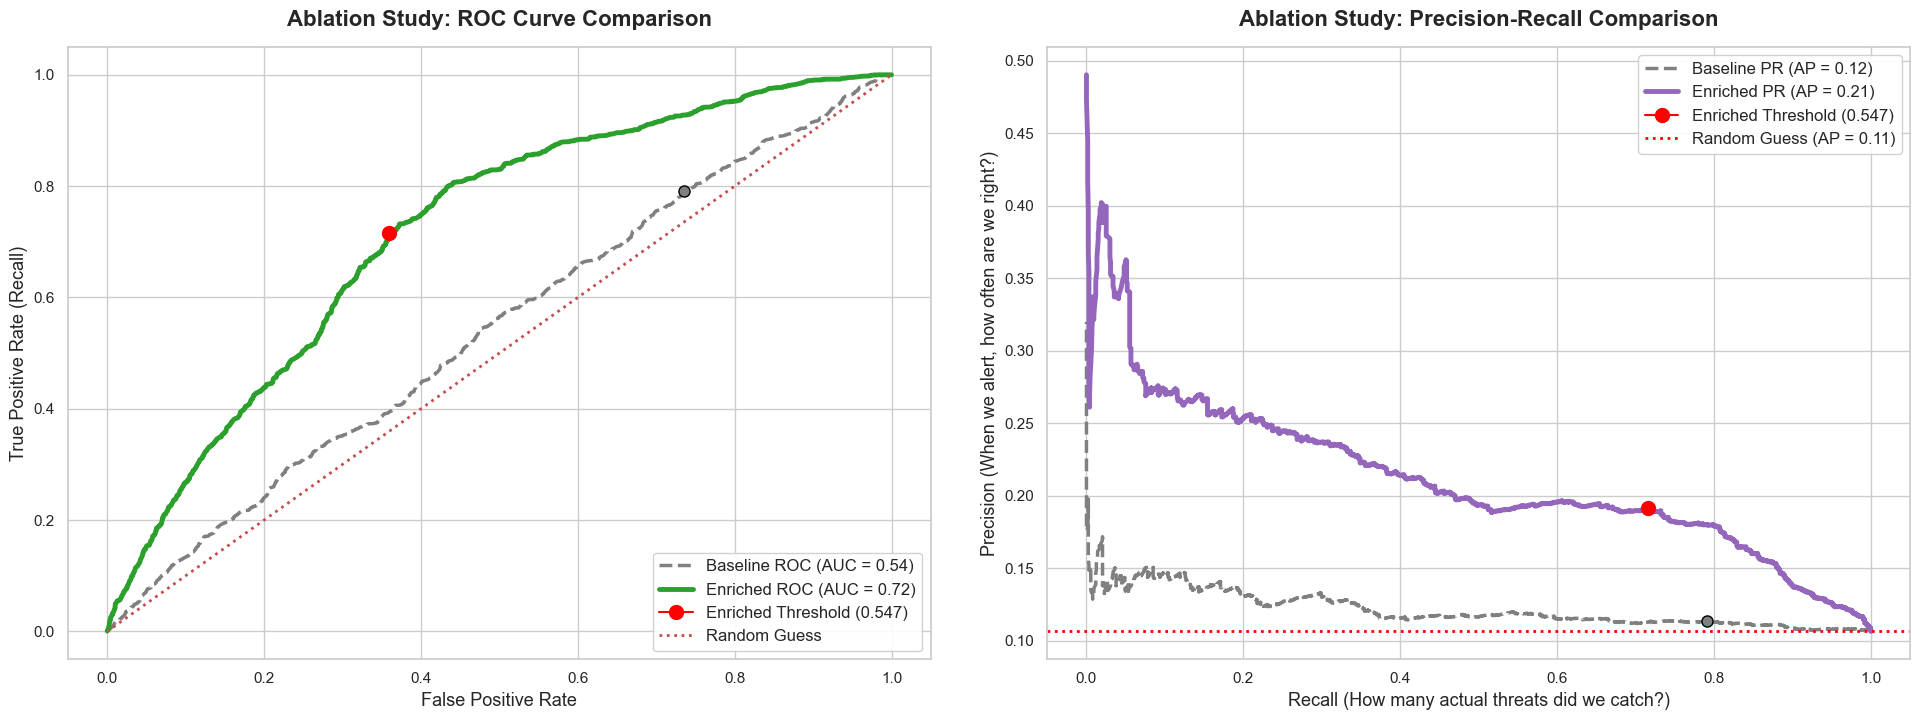

In [14]:
# Note: I noticed in your code you had Enriched ROC as green (#2ca02c) and Enriched PR as purple (#9467bd). 
# Feel free to adjust the colors inside your function to whatever you prefer!

print("==========================================")
print(" CHAPTER 3: THE FINAL ABLATION STUDY      ")
print("==========================================")

fig_ablation = plot_ablation_evaluation(y_true_base, y_probs_base, y_true_enr, y_probs_enr)

timestamp_dist = datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f"{timestamp_dist}_final_ablation_study.png", dpi=300, bbox_inches='tight')
plt.show()